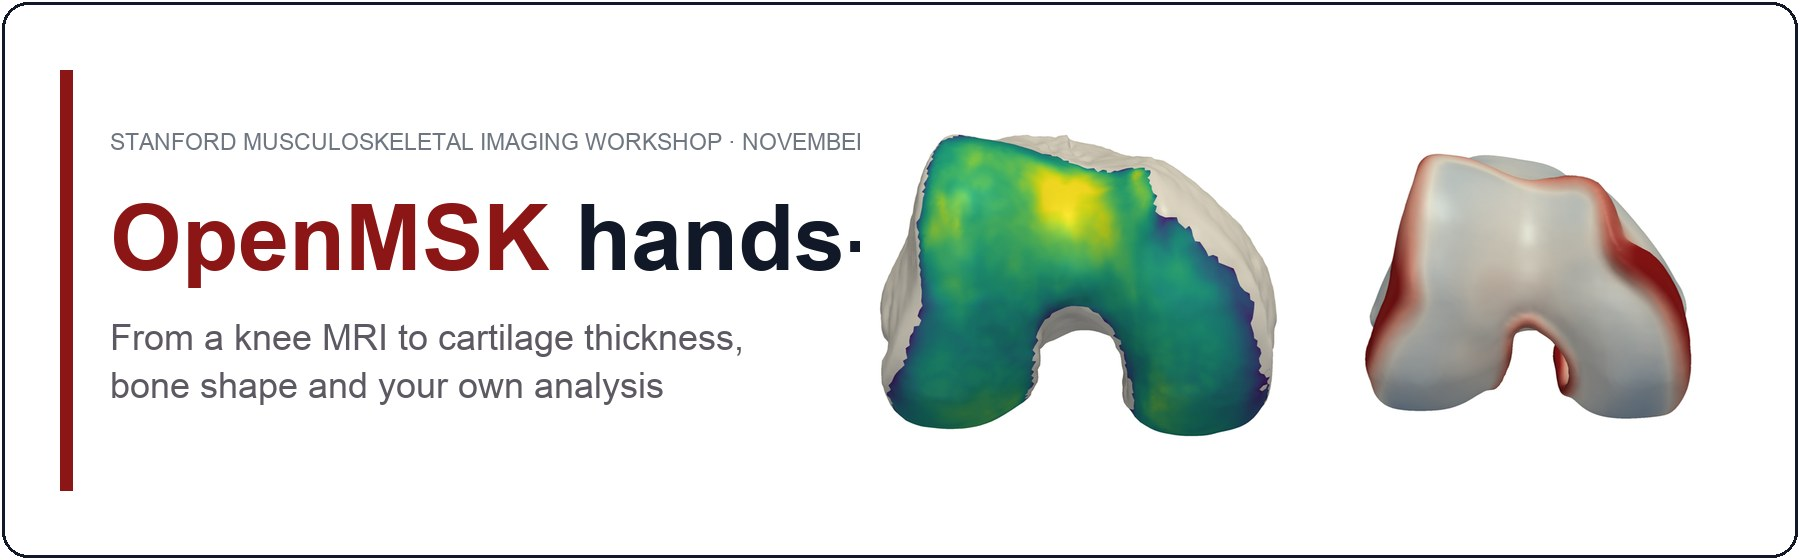

| Step | What happens | Time |
|:--|:--|:--|
| **Setup** | Install what Colab lacks, get the data | 3 min |
| **Part 1 · Run OpenMSK** | What to upload to openmsk.com and which options to pick | 5 min |
| **Part 2 · Open the results** | Every output for the example knee: labels, meshes, thickness, shape model, B-score | 10 min |
| **Part 3 · Many knees** | 500 OAI knees: what is in the sheet, then 5 minutes to explore it yourself | 8 min |
| **Part 4 · B-score analyses** | The two B-scores, thickness by KL, pain, knee replacement | 6 min |
| **Part 5 · See the shape** | What the model stores, knees nobody has, and predict-then-look for sex and pain | 13 min |
| **Part 6 · Your turn** | Pick a question, change a few lines, tell the room what you find | 12 min |

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/NeuromuscularInsightLab/Stanford_Musculoskeletal_Imaging_Workshop/blob/main/notebooks/OpenMSK_hands_on.ipynb)

# Start here: what is OpenMSK, and what will we do?

* **OpenMSK** is a free, open-source pipeline for knee MRI. You upload a scan at [openmsk.com](https://openmsk.com), and it automatically segments the bones, cartilage and menisci
* From those segmentations it measures the knee: 3D meshes, cartilage thickness, T2, a shape-model fit and a B-score for bone shape. Everything comes back as one zip
* **This notebook doesn't run OpenMSK. It starts from the results.** You'll see how a scan goes in, open the zip for one example knee, then analyse 500 example knees that already have results
* By the end, you can do the same with your own scans

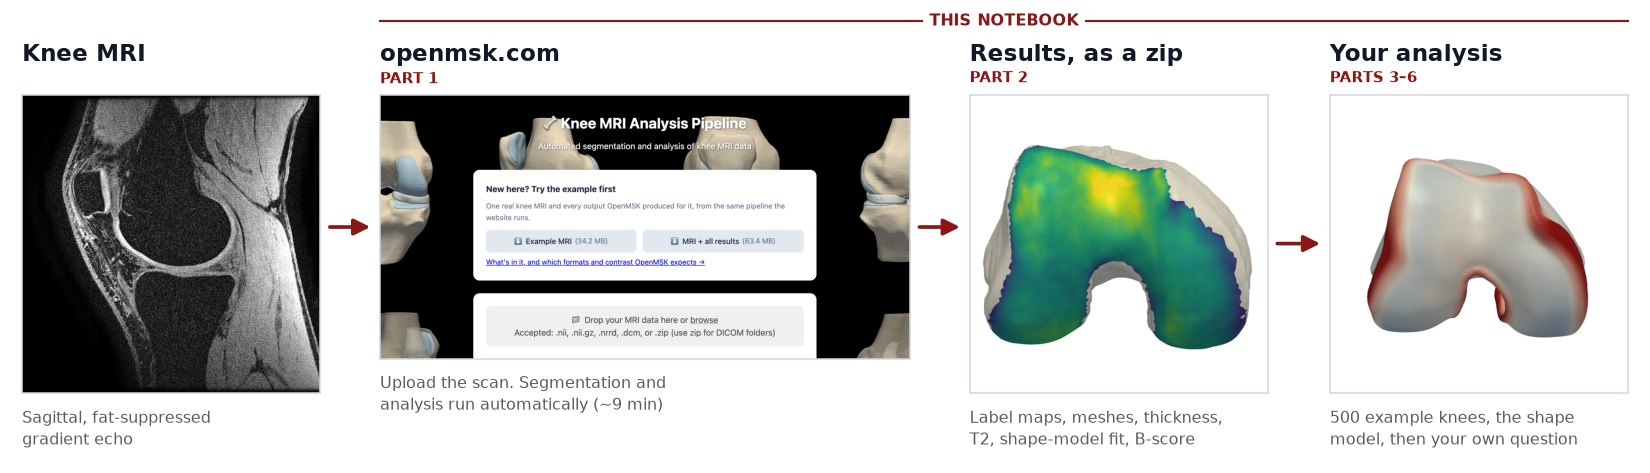

* **Finding your way:** open the table of contents (the list icon at the top of Colab's left sidebar) to jump between parts
* Click the arrow beside a part's title to fold that part away

# Setup · Get the notebook running

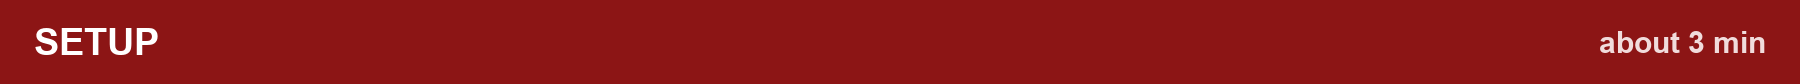

> **In this part:** run one cell. It installs the packages and copies the example data.


* **In Colab:** run the next cell. It installs what Colab doesn't have and copies this repository, data included
* For a faster Part 5, choose **Runtime → Change runtime type → T4 GPU** first. Everything else runs on the CPU
* **On your own computer:** make the `openmsk-workshop` environment ([README, Option 2](https://github.com/NeuromuscularInsightLab/Stanford_Musculoskeletal_Imaging_Workshop/blob/main/README.md#openmsk-local)), then start Jupyter in this repository. The next cell does nothing outside Colab
* Stuck on the install? [`OpenMSK_LLM_prompts.md`](https://github.com/NeuromuscularInsightLab/Stanford_Musculoskeletal_Imaging_Workshop/blob/main/notebooks/OpenMSK_LLM_prompts.md) has prompts that walk an AI assistant through the setup with you

In [ ]:
import os           # files and folders
import subprocess   # run shell commands from Python
import sys          # tells us which Python is running, and where

# Are we inside Google Colab? Colab loads a module called google.colab.
IN_COLAB = "google.colab" in sys.modules
REPO = "https://github.com/NeuromuscularInsightLab/Stanford_Musculoskeletal_Imaging_Workshop"

if IN_COLAB:
    # PyVista draws with OpenGL. These system libraries let it draw without a screen.
    subprocess.run("apt-get -qq update && apt-get -qq install -y libegl1 libgl1 libglx-mesa0 libosmesa6 > /dev/null",
                   shell=True, check=True)
    # Python packages Colab doesn't already have: 3D meshes, medical image formats, mesh repair.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyvista", "trame-pyvista", "pynrrd", "SimpleITK",
                    "nibabel", "pyacvd", "cycpd", "point-cloud-utils", "pymeshfix", "nest_asyncio2", "plotly"], check=True)
    # The shape model code, without its full dependency trees (Colab already has torch and friends).
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-deps", "mskt",
                    "git+https://github.com/gattia/NSM"], check=True)
    # Copy this repository, data included. If it's already here from an earlier run, update it instead.
    if not os.path.exists("/content/workshop"):
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, "/content/workshop"], check=True)
    else:
        subprocess.run(["git", "-C", "/content/workshop", "pull", "-q"], check=False)
    # Work from the notebooks folder, so the helper file and the data paths are found.
    os.chdir("/content/workshop/notebooks")

print("Working in", os.getcwd())

In [ ]:
import json               # read the .json files OpenMSK returns
from pathlib import Path  # file paths that work on any operating system

import matplotlib.pyplot as plt  # 2D plots
import numpy as np               # arrays and maths
import pandas as pd              # tables
import pyvista as pv             # 3D meshes: reading, measuring and drawing them
from IPython.display import Image, display  # show saved pictures in the notebook

import openmsk_helpers as H  # the small helper file next to this notebook. Open it to see how each step works

H.style()     # consistent fonts and colours for every plot
OUT = H.OUT   # folder where figures are saved

# Part 1 · Run OpenMSK: upload a scan at openmsk.com

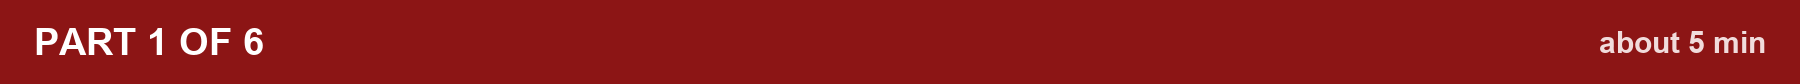

> **In this part:** see how a scan goes into OpenMSK, what to upload and which options to pick. There's nothing to run here.


* [openmsk.com](https://openmsk.com): upload a knee MRI, get every output back as a zip. Nothing to install
* **Please don't upload during the session.** One GPU and about 9 minutes per scan: a room of uploads would queue for hours
* Everything below uses the example knee, which is in this repository at `data/OpenMSK/example/`
* **Get the example yourself:** on the site, *New here? Try the example first* → **MRI + all results**. Same files as `data/OpenMSK/example/` in this repository

<img src="https://raw.githubusercontent.com/NeuromuscularInsightLab/Stanford_Musculoskeletal_Imaging_Workshop/main/assets/openmsk/website_top.png" width="560" alt="The top of openmsk.com, with the example downloads">

**What your scan should look like:**

* Sagittal
* Gradient echo with fat suppression or water excitation: bright cartilage, dark marrow
* The whole joint in view
* NRRD, NIfTI or a zipped DICOM folder, up to 150 MB
* T2 maps need a two-echo qDESS DICOM series

**Choose the segmentation model:**

* The OpenMSK paper tested three U-Net-based models. All three are released and on the menu: the Goyal 2024 sagittal 2D U-Net (recommended), nnU-Net FullRes and nnU-Net Cascade
* Single-plane 2D U-Nets (sagittal, coronal, axial) are released too, if those are of interest

<img src="https://raw.githubusercontent.com/NeuromuscularInsightLab/Stanford_Musculoskeletal_Imaging_Workshop/main/assets/openmsk/website_upload.png" width="560" alt="Upload area, email, and segmentation model menu">

**Choose what to run:**

* **3D surface meshes and cartilage thickness:** leave on. Every later step needs the meshes
* *Cartilage smoothing* blurs the cartilage mask before its surface is made. Leave the default; Part 2 shows what it changes
* **T2 mapping:** leave on. It needs a two-echo qDESS DICOM series, and is skipped if the scan isn't compatible.
* **Neural shape model:** choose what is useful for you
  * It's the slowest step. Leave it off if not of interest.
  * The original shape modeling was done on bone. If bone shape is your main interest, pick **Bone only**
  * **Both** gives you the bone-only and the bone + cartilage fits

<img src="https://raw.githubusercontent.com/NeuromuscularInsightLab/Stanford_Musculoskeletal_Imaging_Workshop/main/assets/openmsk/website_steps.png" width="560" alt="Pipeline steps, with Both selected for the shape model">

**Read the data-handling box.** Upload de-identified data only. What OpenMSK does to protect privacy:

* Your file is converted to NRRD, which strips the DICOM headers
* The file you uploaded is deleted within 24 hours
* The converted image and the results are kept to improve OpenMSK

<img src="https://raw.githubusercontent.com/NeuromuscularInsightLab/Stanford_Musculoskeletal_Imaging_Workshop/main/assets/openmsk/website_consent.png" width="560" alt="Data handling text and the terms checkbox">

# Part 2 · Open the results: what OpenMSK returns for one knee

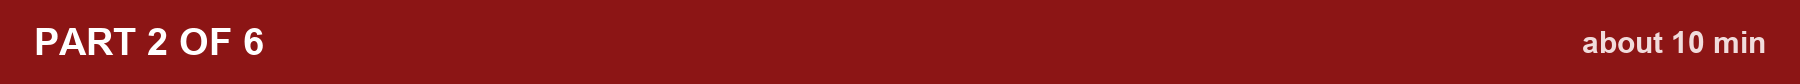

> **In this part:** open the zip OpenMSK sends back for one example knee: label maps, meshes, cartilage thickness, the shape-model fit and the B-score.


* All the returned files in the .zip
* This example is at `data/OpenMSK/example/`. In Colab that's `/content/workshop/data/OpenMSK/example/`
* The same cells work on your own unzipped data: point `FOLDER` at your unzipped folder and change `SCAN`

In [ ]:
import nrrd  # reads .nrrd images

# Where the results live. The example knee ships with this repository, in data/OpenMSK/example/
# (in Colab: /content/workshop/data/OpenMSK/example/).
FOLDER = H.get_example_bundle()     # your own: Path("path/to/unzipped/results")
SCAN = "openmsk-example-knee"       # your own: the name of the file you uploaded

# List every file and its size in megabytes.
rows = [(p.name, round(p.stat().st_size / 1e6, 2)) for p in sorted(FOLDER.iterdir()) if p.is_file()]
pd.DataFrame(rows, columns=["file", "MB"])

## Run records: start here

* `_step_log.json`: which steps finished
* `job_manifest.json`: the model and settings used. Enables reproducibility. 
* T2 is `skipped` here because the example is a single-volume NRRD (FSPGR).

In [ ]:
# Which steps finished, and which were skipped
print(json.dumps(json.loads((FOLDER / "_step_log.json").read_text()), indent=1))
# The model and settings that produced these results
print(json.dumps(json.loads((FOLDER / "job_manifest.json").read_text()), indent=1))

## Segmentation: label maps

* Integer labels on the same voxel grid as the input image
* This identifies what label #s relate to what tissue. Older outputs used different numbers.

In [ ]:
# Read the MRI and the two label maps. Each is a 3D array plus a header describing its geometry.
img, img_header = nrrd.read(FOLDER / f"{SCAN}.nrrd")
labels, _ = nrrd.read(FOLDER / f"{SCAN}_all-labels.nrrd")
subregions, _ = nrrd.read(FOLDER / f"{SCAN}_subregions-labels.nrrd")
# Voxel size in mm, from the header, and the volume of one voxel in mL (1 mL = 1000 mm³).
spacing = np.linalg.norm(np.array(img_header["space directions"], dtype=float), axis=1)
voxel_ml = spacing.prod() / 1000
print("shape", img.shape, "| spacing (mm)", spacing.round(3))

# Two label schemes exist. Native: the example and older jobs. Canonical: the current pipeline's remapped set.
# The femur is the biggest thing in the image, so use it to tell which one this file uses.
NATIVE = {1: "patellar cartilage", 2: "femoral cartilage", 3: "medial tibial cartilage", 4: "lateral tibial cartilage",
          5: "medial meniscus", 6: "lateral meniscus", 7: "femur", 8: "tibia", 9: "patella"}
CANONICAL = {1: "femur", 2: "tibia", 3: "patella", 4: "femoral cartilage", 5: "medial tibial cartilage",
             6: "lateral tibial cartilage", 7: "patellar cartilage", 8: "medial meniscus", 9: "lateral meniscus"}
values, counts = np.unique(labels[labels > 0], return_counts=True)   # every label, and how many voxels it has
NAMES = NATIVE if values[counts.argmax()] == 7 else CANONICAL       # the biggest label is the femur
print("Label scheme:", "native" if NAMES is NATIVE else "canonical")
# Volume of each structure: voxel count times voxel volume.
pd.DataFrame([(k, n, round((labels == k).sum() * voxel_ml, 1)) for k, n in NAMES.items()],
             columns=["label", "structure", "volume_mL"])

In [ ]:
# One colour per structure, then the same colours keyed by label number for this file's scheme.
BY_NAME = {"patellar cartilage": "#F2C14E", "femoral cartilage": "#3FA7D6", "medial tibial cartilage": "#59CD90",
           "lateral tibial cartilage": "#2E8B57", "medial meniscus": "#EE6352", "lateral meniscus": "#B5342B",
           "femur": "#E9E4D8", "tibia": "#C9BFA6", "patella": "#A89B7E"}
COLORS = {k: BY_NAME[n] for k, n in NAMES.items()}
LABEL_OF = {n: k for k, n in NAMES.items()}   # look up a label number by name, e.g. LABEL_OF["femur"]

def overlay(ax, slice_index, label_map, colors, alpha=0.6):
    """Draw one sagittal slice, with the label map on top if one is given."""
    # This scan: first index runs anterior to posterior, second superior to inferior, so .T shows it upright.
    a = img[:, :, slice_index].T.astype(float)
    ax.imshow(np.clip(a / np.percentile(a, 99.6), 0, 1), cmap="gray")   # scale brightness, ignoring the brightest 0.4%
    if label_map is not None:
        lab = label_map[:, :, slice_index].T
        rgba = np.zeros(lab.shape + (4,))           # a transparent colour image the size of the slice
        for k, c in colors.items():
            rgba[lab == k, :3] = plt.matplotlib.colors.to_rgb(c)   # paint each structure its colour
            rgba[lab == k, 3] = alpha                               # and make it partly see-through
        ax.imshow(rgba, interpolation="nearest")
    ax.axis("off")

# Pick the slice in the middle of the medial tibial cartilage.
medial_slice = int(np.median(np.where((labels == LABEL_OF["medial tibial cartilage"]).any(axis=(0, 1)))[0]))
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
overlay(axes[0], medial_slice, None, COLORS)     # left: the MRI alone
overlay(axes[1], medial_slice, labels, COLORS)   # right: with the segmentation
fig.savefig(OUT / "01_segmentation_overlay.png")
plt.show()

## Meshes: thickness lives on the bone

* `femur_mesh.vtk` carries a per-vertex `thickness (mm)` array and a `labels` array
* The cartilage meshes have no array data. 


In [ ]:
# Surface meshes are .vtk files. pv.read loads each one as a mesh of points and triangles.
femur = pv.read(FOLDER / "femur_mesh.vtk")
tibia = pv.read(FOLDER / "tibia_mesh.vtk")
patella = pv.read(FOLDER / "patella_mesh.vtk")
femoral_cartilage = pv.read(FOLDER / "femur_cart_0_mesh.vtk")
# point_data holds the values stored at each point of the mesh
print("femur arrays:", femur.point_data.keys())
print("femoral cartilage arrays:", femoral_cartilage.point_data.keys())

In [ ]:
axis = H.condyle_axis(femur)            # the line joining the condyles, used to level every view
thick = femur["thickness (mm)"].copy()   # cartilage thickness at each point on the bone
thick[thick <= 0] = np.nan             # 0 means no cartilage: show it as bone
femur["t"] = thick                      # store it on the mesh under a short name
# Draw the femur from below, coloured by thickness, and save the picture.
H.render([(femur, dict(scalars="t", cmap="viridis", clim=(0, 3.5), nan_color=H.BONE))],
         H.camera(femur, "trochlea", axis=axis), OUT / "01_femur_thickness.png", size=(800, 800))
display(Image(OUT / "01_femur_thickness.png", width=420))

* Interactive version. Drag to rotate, scroll to zoom

In [ ]:
# Same scene, but drawn by your browser so you can rotate it.
H.show3d([(femur, dict(scalars="t", cmap="viridis", clim=(0, 3.5), nan_color=H.BONE))],
          H.camera(femur, "trochlea", axis=axis))

## What cartilage smoothing does

* Before the cartilage surface is made, the cartilage mask is blurred with a Gaussian
* *Cartilage smoothing* on the website is that blur's variance, in mm². The default, 0.3125, is a standard deviation of about 0.56 mm
* The next cell rebuilds the femoral cartilage surface with no blur, the default and a heavy blur, and measures thickness on the same femur each time
* **No blur:** the surface follows the voxels as a staircase, and the thickness map is noisy
* **Heavy blur:** thin cartilage is rounded away until it disappears, and thickness drops
* Whatever you choose, use the same value for every scan in a study

In [ ]:
import contextlib   # lets us hide printed output
import io

import SimpleITK as sitk                        # reads medical images with their geometry
from pymskt.mesh import BoneMesh, CartilageMesh  # the mesh and thickness tools OpenMSK uses

seg = sitk.ReadImage(str(FOLDER / f"{SCAN}_all-labels.nrrd"))   # the label map, with its voxel size and position
SMOOTHING = [0.0, 0.3125, 2.0]          # 0.3125 is the website default
rows = []
fig, axes = plt.subplots(2, len(SMOOTHING), figsize=(12, 7.6))   # top row: cartilage; bottom row: thickness
for j, variance in enumerate(SMOOTHING):
    with contextlib.redirect_stdout(io.StringIO()):          # pymskt prints a line per ray-cast batch
        # Blur the femoral cartilage mask by this much, then build its surface.
        cart = CartilageMesh(seg_image=seg, label_idx=LABEL_OF["femoral cartilage"])
        cart.create_mesh(smooth_image_var=variance)
        # Measure thickness from the same femur surface every time, so only the smoothing changes.
        bone = BoneMesh(mesh=femur.copy(), seg_image=seg, label_idx=LABEL_OF["femur"],
                        list_cartilage_labels=[LABEL_OF["femoral cartilage"]])
        bone.calc_cartilage_thickness(list_cartilage_meshes=[cart])
    t = np.array(bone["thickness (mm)"], dtype=float)
    # One row of the summary table: smoothing, medial weight-bearing thickness (label 12), and cartilage coverage.
    rows.append({"smoothing (mm²)": variance,
                 "medial weight-bearing femur (mm)": round(t[femur["labels"] == 12].mean(), 2),
                 "bone vertices with cartilage": int((t > 0).sum())})
    surface = pv.PolyData(np.asarray(cart.points), np.asarray(cart.faces))   # the cartilage surface as a plain mesh
    shown = femur.copy()
    shown["t"] = np.where(t > 0, t, np.nan)                                   # no cartilage is drawn as bone
    cam = H.camera(femur, "trochlea", axis=axis, zoom=2.7)
    # H.render returns a picture, which imshow puts into the grid
    axes[0, j].imshow(H.render([(surface, dict(color="#7FB2D9", smooth_shading=False))], cam, size=(700, 700)))
    axes[1, j].imshow(H.render([(shown, dict(scalars="t", cmap="viridis", clim=(0, 3.5), nan_color=H.BONE))], cam, size=(700, 700)))
    axes[0, j].set_title(f"smoothing {variance:g}", color=H.INK)
for ax in axes.ravel():
    ax.axis("off")
# Row labels, a shared colour bar, and save.
axes[0, 0].text(-0.06, 0.5, "cartilage surface", transform=axes[0, 0].transAxes, rotation=90, va="center", ha="right", color=H.MUTED)
axes[1, 0].text(-0.06, 0.5, "thickness on the bone", transform=axes[1, 0].transAxes, rotation=90, va="center", ha="right", color=H.MUTED)
fig.subplots_adjust(wspace=0.02, hspace=0.04, right=0.9)
cax = fig.add_axes([0.92, 0.14, 0.012, 0.3])
fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(0, 3.5), "viridis"), cax=cax, label="Thickness (mm)")
fig.savefig(OUT / "01_cartilage_smoothing.png")
plt.show()
pd.DataFrame(rows)

## Thickness table, and proof it matches the mesh

* `*_results.csv`: one row per scan
* 8 regions × mean, SD and median = 24 numbers
* SD is the spread within a region, not a measurement error
* 0 mm on the mesh means no cartilage there
* Every number summarizes the mesh array, so you can make your own regions
* **Known limitation:** regions follow the segmented cartilage, so a full-thickness lesion can drop out of a region instead of counting as 0 mm. Part 4 shows the fix

In [ ]:
results = pd.read_csv(FOLDER / f"{SCAN}_results.csv").iloc[0]   # one row per scan: take the first (only) row
REGIONS = ["ant_fem_cart", "med_wb_fem_cart", "lat_wb_fem_cart", "med_post_fem_cart", "lat_post_fem_cart",
           "med_tib_cart", "lat_tib_cart", "pat_cart"]
# Pull the mean and SD for each region into a small table.
table = pd.DataFrame({"region": REGIONS, "mean_mm": [results[f"{r}_mm_mean"] for r in REGIONS],
                      "sd_mm": [results[f"{r}_mm_std"] for r in REGIONS]})

# Horizontal bar chart, first region at the top.
fig, ax = plt.subplots(figsize=(7.2, 3.8))
y = np.arange(len(table))[::-1]
ax.barh(y, table.mean_mm, color=H.BLUE, height=0.62)
ax.set_yticks(y, table.region.str.replace("_cart", "").str.replace("_", " "))
for yi, v in zip(y, table.mean_mm):
    ax.text(v + 0.03, yi, f"{v:.2f}", va="center", color=H.INK, fontsize=12)   # write the value at the end of each bar
ax.set_xlabel("Mean cartilage thickness (mm)")
ax.tick_params(length=0)
fig.savefig(OUT / "01_thickness_bars.png")
plt.show()

# The table is a summary of the mesh: average the thickness of every femur point labelled 12 and compare.
print("Table:", round(results["med_wb_fem_cart_mm_mean"], 4),
      "| from the mesh, label 12:", round(femur["thickness (mm)"][femur["labels"] == 12].mean(), 4))

## Shape model and B-score

* B-score is not a file. It's the `Bscore` key inside the JSON
* `assd_bone_mm`, next to it, is fit quality: how far the model's surface is from yours. If it's large, don't trust that knee's B-score
* The score is one line of linear algebra, so check it yourself. `load_bscore_model` fetches the direction from the public OpenMSK repo

In [ ]:
# The two shape-model fits: bone only, and bone + cartilage.
bone_only = json.loads((FOLDER / "NSM_bone_only_recon_params.json").read_text())
bone_cart = json.loads((FOLDER / "NSM_recon_params.json").read_text())
latent = np.array(bone_only["latent"]).ravel()   # the knee's shape as 512 numbers

model = H.load_bscore_model("bone_only")   # the B-score direction, mean and SD, from the OpenMSK repo
print("Latent length:", latent.size)
print("Bone-only B-score, from the file:", round(bone_only["Bscore"], 4))
print("Bone-only B-score, by hand:      ", round(float(H.bscore(latent, model)), 4))   # same number, recomputed
print("Bone + cartilage B-score:        ", round(bone_cart["Bscore"], 4))
print("Fit error, bone (mm):            ", round(bone_only["assd_bone_mm"], 3))

**Where does the model disagree with your segmentation?**

* Left to right: your femur as segmented, the shape model's reconstruction, and the reconstruction coloured by how far it sits from your femur
* Drag to rotate
* Look at the back of the shaft, above the condyles: the segmentation has ridges there, and the model's surface is smooth
* Red is where the two disagree
* The top is grey because your femur was cut there before fitting

In [ ]:
# Fewer points, so the interactive view stays light
yours = pv.read(FOLDER / "femur_mesh_NSM_orig.vtk").decimate(0.8)                     # your femur, as segmented
recon = pv.read(FOLDER / "NSM_bone_only_recon_femur_mesh_NSM_orig.vtk").decimate(0.8)  # the shape model's version
error = np.abs(H.signed_distance(recon, yours))   # at each model point, how far away your surface is (mm)
error[np.asarray(recon.points)[:, 2] > yours.bounds[5] - 1] = np.nan   # above the cut: nothing to compare with
print("Model to your surface, mean (mm):", round(float(np.nanmean(error)), 2))

# Lay three copies side by side: yours, the model, and the model coloured by the error.
shift = 1.15 * (yours.bounds[1] - yours.bounds[0])   # a bit more than one bone width
recon_shown = recon.translate((-shift, 0, 0), inplace=False)
error_shown = recon.translate((-2 * shift, 0, 0), inplace=False)
error_shown["error"] = error
scene = yours.merge([recon_shown, error_shown])     # all three together, so the camera can frame them
H.show3d([(yours, {}), (recon_shown, {}),
          (error_shown, dict(scalars="error", cmap=H.error_cmap(), clim=(0, 1.5), nan_color=H.BONE))],
         H.camera(scene, "posterior", axis=axis, zoom=1.9), size=(1000, 450))

## Where does this knee sit?

* A B-score only means something against a reference group
* Its scale is set by OAI knees without OA: they have a mean of 0 and an SD of 1, so about 1.96 is the top of the normal range
* The reference used here is the OAI teaching sheet provided with this tutorial, in `data/OpenMSK/oai_teaching_cohort/`. Part 3 uses it too
* The code loads that sheet and pulls out the B-scores of its KL 0 knees and its KL 4 knees, 100 of each, to show the two distributions
* The black line is the example knee
* How the B-score axis is built is in the shape-modelling talk earlier in the workshop

In [ ]:
# The reference group: the OAI teaching sheet that comes with this tutorial.
cohort = pd.read_csv(H.DATA / "oai_teaching_cohort" / "oai_teaching_cohort.csv")
bins = np.arange(-4, 9.01, 0.5)
fig, ax = plt.subplots(figsize=(7.6, 3.6))
# Histograms of B-score for the sheet's KL 0 and KL 4 knees.
ax.hist(cohort.loc[cohort.kl == 0, "bscore_bone"], bins=bins, color=H.BLUE, alpha=0.8, label="KL 0 (n=100)", rwidth=0.9)
ax.hist(cohort.loc[cohort.kl == 4, "bscore_bone"], bins=bins, color=H.RED, alpha=0.8, label="KL 4 (n=100)", rwidth=0.9)
ax.set_ylim(0, ax.get_ylim()[1] * 1.22)   # headroom for the label
# A vertical line where the example knee sits.
ax.axvline(bone_only["Bscore"], color=H.INK, lw=2)
ax.text(bone_only["Bscore"] + 0.12, ax.get_ylim()[1] * 0.92, f"This knee, {bone_only['Bscore']:.2f}", color=H.INK)
ax.set_xlabel("Bone-only B-score (non-OA SD units)")
ax.set_ylabel("Knees")
ax.legend(frameon=False, loc="upper right")
fig.savefig(OUT / "01_bscore_context.png")
plt.show()

# Part 3 · Many knees: explore a 500-knee OAI dataset

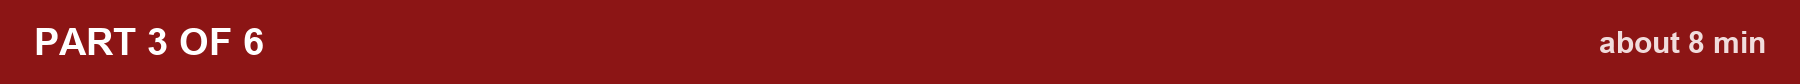

> **In this part:** go from one knee to many. Load 500 OAI knees that already have OpenMSK results, then explore them yourself for 5 minutes.


A small sheet from the Osteoarthritis Initiative, provided with this tutorial in `data/OpenMSK/oai_teaching_cohort/`.

* 500 baseline knees, 100 per KL grade, one knee per person
* Each knee has both B-scores, regional cartilage thickness, pain, and whether it was replaced within 8 years
* The bone-only and bone + cartilage B-scores match closely on average at every KL grade (table below), but not knee by knee. Part 4 shows where they part

In [ ]:
# Load the teaching sheet and look at the first few rows.
cohort = pd.read_csv(H.DATA / "oai_teaching_cohort" / "oai_teaching_cohort.csv")
print(len(cohort), "knees")
cohort.head(3)

In [ ]:
def mean_sd(digits=1):
    """Make a function that formats a column as 'mean (SD)'."""
    return lambda x: f"{x.mean():.{digits}f} ({x.std():.{digits}f})"

g = cohort.groupby("kl")   # one group per KL grade
# One row per KL grade, one column per measure.
summary = pd.DataFrame({
    "n": g.size(),
    "Female (%)": g["sex"].apply(lambda s: round(100 * (s == "Female").mean())),
    "Age (y)": g["age"].apply(mean_sd(1)),
    "BMI (kg/m²)": g["bmi"].apply(mean_sd(1)),
    "B-score, bone": g["bscore_bone"].apply(mean_sd(2)),
    "B-score, bone + cartilage": g["bscore_bone_cart"].apply(mean_sd(2)),
    "Medial WB femur thickness (mm)": g["thick_med_wb_fem_mm"].apply(mean_sd(2)),
    "Pain, NRS 0-10": g["nrs_pain_current"].apply(mean_sd(1)),
    "Knee replacement by 8 y, n (%)": g["tkr_8y"].apply(lambda s: f"{int(s.sum())} ({100 * s.mean():.0f})"),
})
summary.index.name = "KL"
print("Mean (SD) unless noted")
summary

## Explore the sheet yourself (5 min)

* The first cell lists every column: what it means, and what it looks like in these 500 knees
* Then three starter plots. Change the lines marked `change these` and run the cell again
  * Any two columns against each other, with their correlation
  * The correlation between every pair of number columns
  * One column as a histogram, split by group
* Hover over a dot or square to see its details
* The last cell is empty, for anything else you want to try
* The sheet has 100 knees per KL grade, so it isn't a population sample
* Ideas: does cartilage get thinner with age, or with BMI? Which measure tracks pain best? How does pain now relate to pain later?

In [ ]:
# Every column in the sheet: what it means, and what it looks like in these 500 knees
dictionary = pd.read_csv(H.DATA / "oai_teaching_cohort" / "oai_teaching_cohort_data_dictionary.csv")

def in_this_sheet(column):
    """One line per column: counts for text and yes/no columns, the range for numbers."""
    values = cohort[column]
    if not pd.api.types.is_numeric_dtype(values):   # text columns such as sex and side
        if values.nunique() > 10:   # e.g. knee_id: one label per knee
            return f"{values.nunique()} different values"
        return ", ".join(f"{k}: {n}" for k, n in values.value_counts().items())
    if set(values.dropna().unique()) <= {0, 1}:   # yes/no columns: count each answer
        return ", ".join(f"{int(k)}: {n}" for k, n in values.value_counts().sort_index().items())
    low, high = round(float(values.min()), 2), round(float(values.max()), 2)
    return f"{low:g} to {high:g} ({values.notna().sum()} knees)"

dictionary["in this sheet"] = dictionary.column.map(in_this_sheet)
pd.set_option("display.max_colwidth", 140)   # show the descriptions in full
dictionary

In [ ]:
import plotly.express as px   # interactive plots: hover, zoom, and click the legend to hide a group

COLOURS = {**{str(k): c for k, c in enumerate(H.KL_COLORS)}, "Female": H.BLUE, "Male": H.RED}   # the notebook's usual colours

# ---- change these ----
X = "age"                     # any column from the table above
Y = "thick_med_wb_fem_mm"
COLOUR = "kl"                 # a column to colour the dots by, or None
# ----------------------

data = cohort.copy()
if COLOUR is not None and data[COLOUR].nunique() <= 10:   # a few values, like KL or sex: one colour each
    data[COLOUR] = data[COLOUR].astype(str)
pair = data[[X, Y]].dropna()                               # the knees that have both values
r = pair[X].corr(pair[Y])                                  # Pearson correlation: -1 to 1, and 0 means no straight-line link
fig = px.scatter(data, x=X, y=Y, color=COLOUR, color_discrete_map=COLOURS, hover_name="knee_id", template="simple_white", height=480,
                 category_orders={COLOUR: sorted(data[COLOUR].unique())} if COLOUR else None,
                 title=f"r = {r:.2f} across {len(pair)} knees")
fig

In [ ]:
# How strongly each pair of number columns moves together: 1 together, -1 opposite, 0 unrelated
numbers = cohort.select_dtypes("number").drop(columns=["tkr_days"])   # tkr_days exists only for the 61 replaced knees
fig = px.imshow(numbers.corr().round(2), text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1,
                aspect="auto", height=680, title="Correlation between every pair of number columns")
fig

In [ ]:
# ---- change these ----
COLUMN = "thick_med_wb_fem_mm"   # the column to count
BY = "sex"                       # one colour per group, or None
# ----------------------

data = cohort.copy()
if BY is not None:
    data[BY] = data[BY].astype(str)   # treat the groups as labels, not numbers
fig = px.histogram(data, x=COLUMN, color=BY, color_discrete_map=COLOURS, barmode="overlay", opacity=0.6, template="simple_white", height=460,
                   marginal="box",   # a box plot per group above the histogram
                   category_orders={BY: sorted(data[BY].unique())} if BY else None)
fig

In [ ]:
# Your own analysis. Some starting points: delete the # at the start of a line to run it
# cohort.describe()                                    # count, mean, SD and range of every number column
# cohort.groupby("kl").thick_med_tib_mm.mean()         # the mean of one column in each KL grade
# pd.crosstab(cohort.kl, cohort.tkr_8y)                # how many knees fall in each pair of groups
# cohort.plot.scatter("bmi", "womac_pain_current")     # a quick plot without plotly

# Part 4 · Does bone shape track OA, pain and knee replacement?

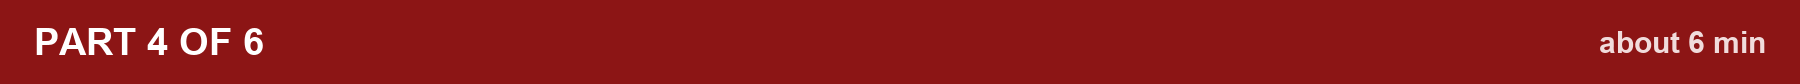

> **In this part:** test the B-score against OA grade, cartilage thickness, pain and knee replacement.


* The B-score against the rest of the sheet: the two B-score versions, cartilage thickness, pain and knee replacement

## Bone-only against bone + cartilage B-score

* Each dot is a knee. On the dashed line, the two B-scores agree
* The six knees furthest from the line are circled, and listed below with their cartilage thickness

In [ ]:
cohort["b_diff"] = cohort.bscore_bone_cart - cohort.bscore_bone   # bone + cartilage minus bone only
# The three knees where bone + cartilage reads highest above bone only, and the three where it reads lowest
discordant = pd.concat([cohort.nlargest(3, "b_diff"), cohort.nsmallest(3, "b_diff")])
r = np.corrcoef(cohort.bscore_bone, cohort.bscore_bone_cart)[0, 1]

fig, ax = plt.subplots(figsize=(6.6, 5.6))
for k in range(5):   # one colour per KL grade
    m = cohort.kl == k
    ax.scatter(cohort.bscore_bone[m], cohort.bscore_bone_cart[m], s=18, color=H.KL_COLORS[k], alpha=0.8,
               linewidths=0, label=f"KL {k}")
lims = [-3, 7.5]
ax.plot(lims, lims, color=H.MUTED, lw=1, ls=(0, (4, 3)))   # the line where the two agree
for row in discordant.itertuples():                         # circle and name the most discordant knees
    ax.scatter(row.bscore_bone, row.bscore_bone_cart, s=70, facecolors="none", edgecolors=H.INK, linewidths=1.2)
    ax.annotate(row.knee_id, (row.bscore_bone, row.bscore_bone_cart), xytext=(7, 7 if row.b_diff > 0 else -12),
                textcoords="offset points", fontsize=10, color=H.INK)
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("Bone-only B-score")
ax.set_ylabel("Bone + cartilage B-score")
ax.text(0.03, 0.95, f"r = {r:.2f}", transform=ax.transAxes, color=H.INK)
ax.legend(frameon=False, loc="lower right")
ax.tick_params(length=0)
fig.savefig(OUT / "02_bscore_bone_vs_bone_cart.png")
plt.show()
discordant[["knee_id", "kl", "sex", "bscore_bone", "bscore_bone_cart", "b_diff", "thick_med_wb_fem_mm", "thick_lat_wb_fem_mm"]].round(2)

## Bone shape and cartilage across KL grades

* Same layout, two measures. Each dot is a knee; the bar is the median
* Watch where each one starts to move

In [ ]:
def by_kl(ax, column, ylabel):
    """One dot per knee, spread sideways a little so they don't overlap, with a bar at each grade's median."""
    rng = np.random.default_rng(1)   # fixed seed, so the spread looks the same every run
    for k in range(5):
        y = cohort.loc[cohort.kl == k, column].values
        ax.scatter(k + rng.uniform(-0.22, 0.22, y.size), y, s=14, color=H.KL_COLORS[k], alpha=0.75, linewidths=0)
        ax.plot([k - 0.3, k + 0.3], [np.median(y)] * 2, color=H.INK, lw=2.4, solid_capstyle="round")
    ax.set_xticks(range(5), [str(k) for k in range(5)])
    ax.set_xlabel("Kellgren-Lawrence grade")
    ax.set_ylabel(ylabel)
    ax.tick_params(length=0)

# B-score by KL grade, with the top of the non-OA range marked.
fig, ax = plt.subplots(figsize=(6.6, 4.6))
by_kl(ax, "bscore_bone", "Bone-only B-score")
ax.axhline(1.96, color=H.MUTED, lw=1, ls=(0, (4, 3)), zorder=0)
ax.set_xlim(-0.5, 5.35)
ax.text(4.45, 1.96, "1.96: top of\nthe non-OA range", color=H.MUTED, fontsize=11, va="center", backgroundcolor="white")
fig.savefig(OUT / "02_bscore_by_kl.png")
plt.show()

# Medial femur thickness by KL grade, same layout.
fig, ax = plt.subplots(figsize=(6.6, 4.6))
by_kl(ax, "thick_med_wb_fem_mm", "Medial weight-bearing\nfemur thickness (mm)")
fig.savefig(OUT / "02_thickness_by_kl.png")
plt.show()

**A current limitation, and the fix**

* The thickness in this sheet is not the website's table
* It comes from Kenzie White's method (her talk earlier in the workshop): the shape model places the same region on every knee, and bone with no cartilage left counts as 0 mm
* That's why KL 4 knees reach close to 0 mm here
* The website's current release defines regions from the segmented cartilage, so a full-thickness lesion drops out instead of counting as 0 mm, and badly damaged knees read thicker than they are
* Cartilage volume may partly help: lost cartilage lowers the volume instead of dropping out of a region
* But cartilage seems to spread out as the bone spreads out, so volume might not fully show the loss either
* The shape-model regions will be released in a future version

## Does it track symptoms?

* Mean current pain in each fifth of the knees, ordered by B-score
* Bars are 95% confidence intervals

In [ ]:
# Sort the knees by B-score into five equal groups (fifths).
cohort["b_bin"] = pd.qcut(cohort.bscore_bone, 5, labels=False)
# For each fifth: mean B-score, mean pain, and the standard error of that mean.
g = cohort.groupby("b_bin").agg(b=("bscore_bone", "mean"), pain=("nrs_pain_current", "mean"),
                               se=("nrs_pain_current", lambda s: s.std() / np.sqrt(len(s))))
fig, ax = plt.subplots(figsize=(6.2, 4.0))
# Mean pain per fifth, with 95% confidence intervals (1.96 standard errors).
ax.errorbar(g.b, g.pain, yerr=1.96 * g.se, color=H.BLUE, lw=2, marker="o", ms=8, mec="white", mew=2, capsize=0)
ax.set_xlabel("Bone-only B-score (mean of each fifth of knees)")
ax.set_ylabel("Current knee pain\n(NRS, 0-10)")
ax.set_ylim(0, None)
ax.set_xticks(np.arange(-1, 5))
ax.set_xlim(-1.3, 4.6)
ax.tick_params(length=0)
fig.savefig(OUT / "02_pain_by_bscore.png")
plt.show()

## Does it say who ends up with a knee replacement?

* **Left:** the 500 knees sorted by bone-only B-score and cut into three equal groups, about 167 knees each. The labels give each group's B-score range
* **Right:** for each group, the share of knees that had a knee replacement over follow-up. Kaplan-Meier handles people followed for different lengths of time
* The higher the B-score, the more knees were replaced
* Look at how far apart the curves are. The sheet has equal numbers per KL grade, so it has more replacements than the OAI as a whole

In [ ]:
THIRDS = ["Low", "Middle", "High"]
COLORS = {"Low": H.KL_COLORS[0], "Middle": H.KL_COLORS[2], "High": H.KL_COLORS[4]}
cohort["third"] = pd.qcut(cohort.bscore_bone, 3, labels=THIRDS)   # sort by B-score, cut into three equal groups

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.2], "wspace": 0.3})

# 1. How the knees are split: sort by B-score, cut into three equal groups
bins = np.arange(-3, 7.01, 0.25)
tallest = 0
for name in THIRDS:
    counts, _, _ = ax0.hist(cohort.loc[cohort.third == name, "bscore_bone"], bins=bins, color=COLORS[name], rwidth=0.9)
    tallest = max(tallest, counts.max())
for name in THIRDS:                                   # one label per third, all at the same height
    b = cohort.loc[cohort.third == name, "bscore_bone"]
    ax0.text((b.min() + b.max()) / 2, tallest * 1.08, f"{name}\n{b.min():.1f} to {b.max():.1f}", ha="center",
             va="bottom", color=H.INK, fontsize=11)
for cut in cohort.groupby("third", observed=True).bscore_bone.max().iloc[:2]:   # dashed lines at the two cut points
    ax0.axvline(cut, color=H.MUTED, lw=1, ls=(0, (4, 3)))
ax0.set_ylim(0, tallest * 1.45)
ax0.set_xlabel("Bone-only B-score")
ax0.set_ylabel("Knees")
ax0.set_title("1 · Split the 500 knees into B-score thirds", loc="left", color=H.INK, fontsize=13)

# 2. Follow each third: share of knees replaced over time (Kaplan-Meier)
labels = []
for name in THIRDS:
    d = cohort[cohort.third == name]
    # Kaplan-Meier handles knees followed for different lengths of time.
    t, inc = H.km_curve(d.followup_days, d.tkr_days.notna())
    ax1.step(t, inc * 100, where="post", color=COLORS[name], lw=2.6)
    labels.append([inc[-1] * 100, f"{name} third: {int(d.tkr_8y.sum())} of {len(d)} replaced", t[-1]])
labels.sort()
for i in range(1, len(labels)):                      # keep the end labels from overlapping
    labels[i][0] = max(labels[i][0], labels[i - 1][0] + 2.6)
for y, text, x in labels:                            # write each label at the end of its curve
    ax1.text(x + 0.12, y, text, color=H.INK, va="center", fontsize=12)
ax1.set_xlim(0, 12.2)
ax1.set_xticks([0, 2, 4, 6, 8])
ax1.set_xlabel("Years from enrolment")
ax1.set_ylabel("Knees replaced (%)")
ax1.set_title("2 · Follow each third for knee replacement", loc="left", color=H.INK, fontsize=13)
for ax in (ax0, ax1):
    ax.tick_params(length=0)
fig.savefig(OUT / "02_tkr_km.png")
plt.show()

# Part 5 · See the shape: turn the numbers back into knees

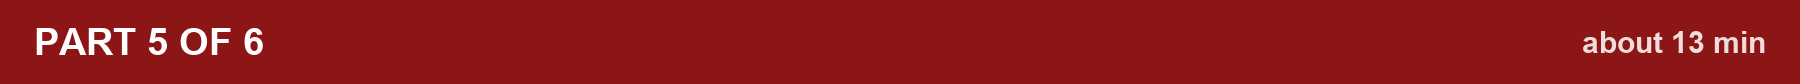

> **In this part:** turn the 512 numbers behind each knee back into a 3D surface, and see what a difference between two groups looks like.


* Every OpenMSK result includes a 512-long `latent`: the knee's shape, written as numbers
* The decoder turns any latent back into a surface
* That includes knees nobody has: the average KL 4 knee, or a knee moved along an axis you made up
* No GPU? It still runs. On a CPU, knees already saved in this repository load instead of being decoded. New knees just take longer: several seconds each
* The decoder downloads from Hugging Face the first time, about 275 MB. No account needed. It's free for non-commercial use: see the [model card](https://huggingface.co/aagatti/ShapeMedKnee)
* If the download fails, the knees below come from copies saved in this repository

In [ ]:
import os

from huggingface_hub import get_token, notebook_login

# Ask for a Hugging Face token only if the model needs one: no local copy, no saved token, and the repo is gated.
from huggingface_hub import hf_hub_download
from huggingface_hub.utils import logging as hf_logging

hf_logging.set_verbosity_error()   # no token is needed; skip the notice suggesting one
if not os.environ.get("NSM_MODEL_DIR") and get_token() is None:
    try:
        hf_hub_download("aagatti/ShapeMedKnee", "551_nsm_femur_bone_v0.0.1/model_params_config.json")   # a tiny file
        print("The shape model is open: no login needed.")
    except Exception:   # gated: log in once
        notebook_login()

In [ ]:
import os

N = int(os.environ.get("NSM_GRID", 128))   # grid size. 128 is fast, 220 is for figures.
# H.decode lightly smooths each surface to hide the grid's small steps (smooth=False turns it off).
# That's this notebook, not NSM: the reconstruction in the zip uses a 256 grid and no smoothing.
FOLDER = H.get_example_bundle()
try:
    decoder = H.load_decoder()             # downloads the shape model the first time (about 275 MB)
    print("Device:", decoder.device_name)  # cuda = GPU, mps = Apple GPU, cpu = processor
except Exception as err:                   # no access: the knees below come from copies saved in this repository
    decoder = None
    print(f"Shape model not loaded ({type(err).__name__}). Using the surfaces saved in this repository.")
model = H.load_bscore_model("bone_only")   # the B-score direction, mean and SD


## Decode the example knee

* Rebuild the surface from the 512 numbers, then compare it with the mesh OpenMSK shipped
* `icp_transform` maps your knee into the model's frame. Its inverse brings the decoded surface back to image space, in mm
* In the 3D view, left is decoded from the numbers and right is the reconstruction in the zip. Drag to rotate

In [ ]:
params = json.loads((FOLDER / "NSM_bone_only_recon_params.json").read_text())
latent = np.array(params["latent"]).ravel()   # the 512 numbers
icp = np.array(params["icp_transform"])       # 4x4 matrix: your knee's position, rotation and size in the model's frame
MM_PER_UNIT = 1 / np.cbrt(np.linalg.det(icp[:3, :3]))   # this knee's size. Used below to put group maps in mm.

surface = H.decode_or_load(decoder, latent, "example", n=N)   # numbers -> surface, in model units
back = surface.transform(np.linalg.inv(icp), inplace=False)  # undo the matrix: back to image space, in mm
shipped = pv.read(FOLDER / "NSM_bone_only_recon_femur_mesh_NSM_orig.vtk")   # the reconstruction in the zip
print("Mean distance to the shipped reconstruction (mm):", round(float(np.abs(H.signed_distance(back, shipped)).mean()), 3))
print("mm per model unit for this knee:", round(float(MM_PER_UNIT), 1))
H.render([(back, {})], H.camera(back, "anterior", axis=H.condyle_axis(back)), OUT / "03_decoded_example.png", size=(800, 800))

# Left: decoded from the 512 numbers. Right: the reconstruction that came in the zip.
in_zip = shipped.decimate(0.8).translate((1.15 * (back.bounds[1] - back.bounds[0]), 0, 0), inplace=False)
H.show3d([(back, {}), (in_zip, {})], H.camera(back.merge(in_zip), "anterior", axis=H.condyle_axis(back), zoom=1.9),
         size=(900, 450))

## What the shape model stores

* The network doesn't store a mesh. It stores a function: give it a point in space plus the 512 numbers, and it returns how far that point is from the bone surface
* Negative inside the bone, positive outside, zero exactly on the surface
* **Left:** those distances on one slice through the knee. The black line, where the distance is zero, is the bone's outline
* **Right:** where that slice sits
* To make a mesh, ask for the distance on a 3D grid and join up the zeros (marching cubes). That's what `H.decode` does
* Change the 512 numbers and the whole field changes smoothly. That's why averaging knees, or moving along a direction, gives sensible bones

In [ ]:
if decoder is None:
    print("This figure needs the shape model itself, which didn't load, so it's skipped.")
else:
    OFFSET = 0.3   # where the slice sits, in model units: through the medial condyle
    u, v, sdf = H.sdf_slice(decoder, latent, plane="sagittal", offset=OFFSET)
    sdf_mm = sdf * MM_PER_UNIT   # model units to mm, using this knee's size
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 4.8))
    # Left: the distance at every point of the slice, and the zero line (the bone's outline)
    shown = ax0.imshow(sdf_mm, extent=(-1, 1, -1, 1), origin="lower", cmap=H.diverging_cmap(), vmin=-15, vmax=15)
    ax0.contour(u, v, sdf_mm, levels=[0], colors=H.INK, linewidths=2)
    ax0.set_xticks([]); ax0.set_yticks([])
    ax0.set_xlabel("anterior  ←       →  posterior")
    ax0.set_ylabel("inferior  ←       →  superior")
    fig.colorbar(shown, ax=ax0, shrink=0.8, label="Distance to the surface (mm)\nnegative inside, positive outside")
    # Right: the decoded knee with the slice drawn through it
    plane = pv.Plane(center=(OFFSET, 0, 0), direction=(1, 0, 0), i_size=2, j_size=2)
    ax1.imshow(H.render([(surface, {}), (plane, dict(color=H.BLUE, opacity=0.35, smooth_shading=False))],
                        H.camera(surface, "antmed", zoom=3.2), size=(700, 700)))
    ax1.axis("off")
    fig.savefig(OUT / "03_sdf_slice.png")
    plt.show()

## Load the cohort's latents

* One 512-long latent per knee in the teaching sheet
* B-scores recomputed from them should match the sheet

In [ ]:
cohort = pd.read_csv(H.DATA / "oai_teaching_cohort" / "oai_teaching_cohort.csv")
# One 512-long latent per knee, reordered to match the sheet's rows.
Z = pd.read_csv(H.DATA / "oai_teaching_cohort" / "oai_teaching_cohort_latents.csv").set_index("knee_id").loc[cohort.knee_id].values
print("Latents:", Z.shape)
# Check: B-scores computed from the latents should match the sheet.
print("B-score recomputed from latents, largest difference from the sheet:",
      round(float(np.abs(H.bscore(Z, model) - cohort.bscore_bone).max()), 5))

DIV = H.diverging_cmap()   # blue (sits in) - bone (no change) - red (sticks out)
CLIM = (-3, 3)             # colour range in mm
H.colorbar(OUT / "03_colorbar.png", "KL 4 vs KL 0 (mm)", *CLIM, DIV, ticks=[-3, -1.5, 0, 1.5, 3])

def show_difference(surface_a, surface_b, name, clim=CLIM, reference=None):
    """Colour surface_b by how far it sits from surface_a. Red sticks out, blue sits in."""
    reference = reference if reference is not None else surface_a
    axis = H.condyle_axis(reference)               # level the views on the reference knee
    d = H.signed_distance(surface_b, surface_a)    # mm, at every point of surface_b
    print(f"{name}: 1st to 99th percentile {np.percentile(d, 1):.2f} to {np.percentile(d, 99):.2f} mm")
    # Three fixed views, saved and shown side by side
    paths = []
    for view in ("anterior", "trochlea", "posterior"):
        p = OUT / f"03_{name}_{view}.png"
        H.render([(surface_b, dict(scalars=d, cmap=DIV, clim=clim))], H.camera(reference, view, axis=axis), p, size=(800, 800))
        paths.append(p)
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
    for ax, p, title in zip(axes, paths, ("Anterior", "Inferior", "Posterior")):
        ax.imshow(plt.imread(p)); ax.set_title(title, color=H.MUTED, fontsize=12); ax.axis("off")
    plt.show()
    # Then the same surface, interactive
    display(H.show3d([(surface_b, dict(scalars=d, cmap=DIV, clim=clim))], H.camera(reference, "trochlea", axis=axis)))

## The latent space: 500 knees as points

* Each knee is 512 numbers: one point in a 512-dimensional space. We can't see 512 dimensions, so squash them to 2
* **PCA** keeps the two directions with the most spread. **t-SNE** keeps knees that are close in 512 dimensions close on the page; distances between far-apart groups mean little
* **Use the menu** to colour the knees by KL grade, sex, pain or B-score. Hover over a dot for that knee's details
* Do the KL grades separate? Does sex? Does pain?

In [ ]:
import plotly.graph_objects as go
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

Zs = StandardScaler().fit_transform(Z)   # put all 512 numbers on the same scale first
embeddings = {
    "PCA": PCA(2, random_state=0).fit_transform(Zs),                               # the two directions with the most spread
    "t-SNE": TSNE(2, perplexity=30, init="pca", random_state=0).fit_transform(Zs),   # keeps neighbours together
}
hover = np.array([f"{r.knee_id}<br>KL {r.kl}, {r.sex}<br>B-score {r.bscore_bone:.1f}<br>pain {r.nrs_pain_current:.0f}/10"
                  for r in cohort.itertuples()])
traces, options = [], []   # options[i]: which menu choice trace i belongs to

def add(xy, mask, name, option, legend=True, **marker):
    """One group of dots. Colour arrays are cut down to the same knees as the dots."""
    m = np.asarray(mask, bool)
    marker = {k: (np.asarray(v)[m] if k == "color" and np.ndim(v) else v) for k, v in marker.items()}
    traces.append(go.Scatter(x=xy[m, 0], y=xy[m, 1], mode="markers", name=name, showlegend=legend,
                             marker=dict(size=7, opacity=0.85, **marker), text=hover[m], hoverinfo="text"))
    options.append(option)

everyone = np.ones(len(cohort), bool)
for emb, xy in embeddings.items():
    for k in range(5):                                           # coloured by KL grade
        add(xy, cohort.kl == k, f"KL {k}", f"{emb} · KL grade", color=H.KL_COLORS[k])
    for sex, color in (("Female", H.BLUE), ("Male", H.RED)):    # coloured by sex
        add(xy, cohort.sex == sex, sex, f"{emb} · sex", color=color)
    add(xy, everyone, "pain", f"{emb} · pain", legend=False, color=cohort.nrs_pain_current, colorscale="Reds",
        cmin=0, cmax=10, colorbar=dict(title="Pain, NRS"))
    add(xy, everyone, "B-score", f"{emb} · B-score", legend=False, color=cohort.bscore_bone, colorscale="Reds",
        cmin=-2, cmax=6, colorbar=dict(title="B-score"))

menu = list(dict.fromkeys(options))   # the menu choices, in order
start = "t-SNE · KL grade"
fig = go.Figure(traces)
for trace, option in zip(fig.data, options):
    trace.visible = option == start   # only one colouring visible at a time
fig.update_layout(
    height=560, margin=dict(l=10, r=10, t=60, b=10), plot_bgcolor="white", paper_bgcolor="white",
    xaxis=dict(showticklabels=False, showgrid=False, zeroline=False), yaxis=dict(showticklabels=False, showgrid=False, zeroline=False),
    # The menu: each choice shows its own group of dots and hides the rest.
    updatemenus=[dict(active=menu.index(start), x=0, y=1.13, xanchor="left",
                      buttons=[dict(label=o, method="update", args=[{"visible": [x == o for x in options]}]) for o in menu])],
)
fig

## Group difference 1: the average KL 0 and KL 4 knee

* Average the latents in each group, then decode
* Colour the KL 4 surface by its distance from the KL 0 surface: red sticks out, blue sits in
* Sizes are normalised before fitting, so this is shape, not size
* To read it in mm, the map uses one knee's scale
* Each map below comes as three fixed views, then a 3D view you can rotate

In [ ]:
# Average the latents of each group, then turn each average into a surface.
mean_kl0 = H.decode_or_load(decoder, Z[cohort.kl == 0].mean(0), "mean_kl0", n=N, mm_per_unit=MM_PER_UNIT)
mean_kl4 = H.decode_or_load(decoder, Z[cohort.kl == 4].mean(0), "mean_kl4", n=N, mm_per_unit=MM_PER_UNIT)
axis = H.condyle_axis(mean_kl0)
# Save plain pictures of the average KL 0 knee from three sides.
for view in ("anterior", "trochlea", "posterior"):
    H.render([(mean_kl0, {})], H.camera(mean_kl0, view, axis=axis), OUT / f"03_mean_kl0_{view}.png", size=(800, 800))
show_difference(mean_kl0, mean_kl4, "kl4_vs_kl0")   # colour the KL 4 knee by its distance from the KL 0 knee

## Where the B-score comes from

* Start with the knees as points in shape space: KL 0 knees in blue, KL 2 or more in red, on the two directions with the most spread
* The line joins the average KL 0 knee to the average OA knee. That's the OA direction
* **Drag the slider:** the view turns until that direction runs left to right, then every knee drops onto it
* Where a knee lands is its B-score: 0 is the average non-OA knee, and 1 unit is one non-OA SD
* The next section walks a knee along this same line

In [ ]:
from scipy.stats import gaussian_kde

healthy, oa = (cohort.kl == 0).values, (cohort.kl >= 2).values
v = model["vector"]
vhat = v / np.linalg.norm(v)                   # the B-score direction, unit length
scale = np.linalg.norm(v) / model["std"]       # latent units to B-score units
pcs = PCA(2, random_state=0).fit(Z).components_   # the two directions with the most spread
e1 = pcs[0]
e2 = pcs[1] - (pcs[1] @ e1) * e1
e2 /= np.linalg.norm(e2)
mid = (Z[healthy].mean(0) + Z[oa].mean(0)) / 2   # halfway between the two group averages
b_mid = float(H.bscore(mid, model))
theta = np.arctan2(vhat @ e2, vhat @ e1)       # where the B-score direction points in the PC1-PC2 plane

def view(t, squash):
    """A 2D view turned a fraction t of the way to the B-score axis, with the vertical spread squashed."""
    x = np.cos(theta * t) * e1 + np.sin(theta * t) * e2
    y = -np.sin(theta * t) * e1 + np.cos(theta * t) * e2
    x = (1 - t) * x + t * vhat                 # end exactly on the B-score direction
    x /= np.linalg.norm(x)
    y = y - (y @ x) * x
    y /= np.linalg.norm(y)
    return lambda pts: ((pts - mid) @ x * scale + t * b_mid, (pts - mid) @ y * scale * (1 - squash))

# The stages of the story: (turn, squash, show averages, show distributions, title)
STAGES = ([(0, 0, False, False, "1 · Shape space: the two directions with the most spread"),
           (0, 0, True, False, "2 · The average KL 0 knee and the average OA knee")]
          + [(t, 0, True, False, "3 · Turn until the OA direction runs left to right") for t in np.linspace(0.2, 1, 5)]
          + [(1, s, True, False, "4 · Drop every knee onto that line") for s in (0.4, 0.75, 1.0)]
          + [(1, 1, True, True, "5 · Where each knee lands is its B-score")])

# The two distributions for the last stage, scaled to sit above the line
grid = np.linspace(-4, 9, 300)
b_h, b_o = H.bscore(Z[healthy], model), H.bscore(Z[oa], model)
kde_h, kde_o = gaussian_kde(b_h)(grid), gaussian_kde(b_o)(grid)
lift = 3.0 / max(kde_h.max(), kde_o.max())

def stage_data(t, squash, means, kdes):
    """x, y and visibility for every trace at one stage."""
    project = view(t, squash)
    hx, hy = project(Z[healthy])
    ox, oy = project(Z[oa])
    mx, my = project(np.vstack([Z[healthy].mean(0), Z[oa].mean(0)]))
    return dict(x=[hx, ox, mx, grid, grid], y=[hy, oy, my, kde_h * lift, kde_o * lift],
                visible=[True, True, means, kdes, kdes])

first = stage_data(*STAGES[0][:4])
fig = go.Figure([
    go.Scatter(name="KL 0", mode="markers", marker=dict(size=6, color=H.BLUE, opacity=0.6)),
    go.Scatter(name="KL 2 or more", mode="markers", marker=dict(size=6, color=H.RED, opacity=0.5)),
    go.Scatter(name="group averages", mode="lines+markers", line=dict(color=H.INK, width=3),
               marker=dict(size=13, color=[H.BLUE, H.RED], line=dict(color="white", width=2))),
    go.Scatter(name="KL 0 B-scores", mode="lines", line=dict(color=H.BLUE, width=3), fill="tozeroy"),
    go.Scatter(name="KL 2+ B-scores", mode="lines", line=dict(color=H.RED, width=3), fill="tozeroy"),
])
for i, trace in enumerate(fig.data):
    trace.update(x=first["x"][i], y=first["y"][i], visible=first["visible"][i], hoverinfo="skip")

# Fixed axes for every stage, so only the knees move
all_x = np.concatenate([np.concatenate(stage_data(*s[:4])["x"][:2]) for s in STAGES])
all_y = np.concatenate([np.concatenate(stage_data(*s[:4])["y"][:2]) for s in STAGES])
fig.update_layout(
    height=520, margin=dict(l=10, r=10, t=60, b=10), plot_bgcolor="white", paper_bgcolor="white",
    title=STAGES[0][4], legend=dict(x=0, y=1),
    # Same scale on both axes, so the turn is a true rotation. "domain" narrows the plot instead of stretching the axis.
    xaxis=dict(range=[min(all_x.min(), grid.min()) - 0.5, max(all_x.max(), grid.max()) + 0.5], constrain="domain",
               showgrid=False, zeroline=False, showticklabels=False),
    yaxis=dict(range=[all_y.min() - 0.5, max(all_y.max(), 3.3) + 0.5], showgrid=False, zeroline=False,
               showticklabels=False, scaleanchor="x", scaleratio=1),
    sliders=[dict(active=0, currentvalue=dict(visible=False), pad=dict(t=10),
                  steps=[dict(label=str(i + 1), method="update",
                              args=[stage_data(*s[:4]),
                                    {"title.text": s[4], "xaxis.showticklabels": s[0] == 1, "xaxis.title.text": "B-score" if s[0] == 1 else ""}])
                         for i, s in enumerate(STAGES)])],
)
fig

## Group difference 2: walk along the B-score axis

* The B-score is a direction in latent space
* Start at the average KL 0 knee and move it from B = −2 to B = 6
* Nobody has these knees: the model is showing you what the score means
* Colour is distance from the B = 0 knee
* **Drag the slider** to walk along the axis, and drag the knee to rotate it

In [ ]:
start = Z[cohort.kl == 0].mean(0)   # the average KL 0 knee
SLIDER = tuple(range(-2, 7))        # every whole B-score from -2 to 6, for the slider
PICTURES = (-2, -1, 0, 2, 4, 6)     # the ones shown as pictures
# Move it along the B-score direction to each B-score, and decode each one.
walk = {b: H.decode_or_load(decoder, H.move_to_bscore(start, b, model), f"walk_b{b:+d}", n=N, mm_per_unit=MM_PER_UNIT)
        for b in SLIDER}
fig, axes = plt.subplots(1, len(PICTURES), figsize=(16, 3.4))
for ax, b in zip(axes, PICTURES):
    s = walk[b]
    d = H.signed_distance(s, walk[0])   # how far each knee sits from the B = 0 knee
    print(f"B = {b}: 1st to 99th percentile {np.percentile(d, 1):.2f} to {np.percentile(d, 99):.2f} mm")
    img = H.render([(s, dict(scalars=d, cmap=DIV, clim=(-5, 5)))], H.camera(walk[0], "trochlea", axis=axis),
                   OUT / f"03_walk_b{b}_trochlea.png", size=(800, 800))
    H.render([(s, dict(scalars=d, cmap=DIV, clim=(-5, 5)))], H.camera(walk[0], "anterior", axis=axis),
             OUT / f"03_walk_b{b}_anterior.png", size=(800, 800))
    ax.imshow(img); ax.set_title(f"B = {b}", color=H.INK); ax.axis("off")
fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(-5, 5), DIV), ax=axes, shrink=0.8, label="Distance from B = 0 (mm)")
H.colorbar(OUT / "03_colorbar_walk.png", "Distance from B = 0 (mm)", -5, 5, DIV, ticks=[-5, -2.5, 0, 2.5, 5])
plt.show()

# Drag the slider to walk along the B-score axis. Drag the knee to rotate it.
H.morph_viewer(walk, walk[0], clim=(-5, 5), label="mm from B = 0", prefix="B-score: ", start=0, view="trochlea", axis=axis)

## Group difference 3: predict first, then look. Female and male

* Before decoding a difference, check that it's real: can the 512 numbers predict the group on knees the model hasn't seen?
* **Bootstrap:** draw 500 knees with replacement, fit a logistic regression, then score it on the knees that weren't drawn. Repeat 100 times
* The ROC curve shows the same thing for one 5-fold cross-validation: every knee scored by a model that never saw it
* Sizes are normalised before fitting, so this is shape, not size. Bigger knees can still have different proportions, so some of the signal may be size in disguise
* If the prediction holds up, the regression's weights are a direction in latent space. Decode knees along it to see what the model is using
* **Drag the slider** to move from the male end to the female end

In [ ]:
from sklearn.linear_model import LogisticRegression   # a simple classifier
from sklearn.metrics import roc_auc_score, roc_curve  # area under the ROC curve: 0.5 is chance, 1.0 is perfect
from sklearn.model_selection import StratifiedKFold, cross_val_predict

def bootstrap_axis(X, y, n_boot=100, C=0.03, seed=0):
    """Fit a logistic regression on resampled knees and score it on the knees left out, n_boot times.

    Returns the held-out AUCs, and the average direction of the fits (unit length) in latent space.
    """
    rng = np.random.default_rng(seed)    # fixed seed, so the result is the same every run
    aucs, directions = [], []
    for _ in range(n_boot):
        train = rng.integers(0, len(y), len(y))              # draw knees with replacement
        test = np.setdiff1d(np.arange(len(y)), train)        # the knees never drawn: held out
        if len(set(y[train])) < 2 or len(set(y[test])) < 2:  # need both groups on each side
            continue
        fit = LogisticRegression(C=C, max_iter=5000).fit(X[train], y[train])   # C sets how strongly weights are shrunk
        aucs.append(roc_auc_score(y[test], fit.decision_function(X[test])))    # how well it ranks the held-out knees
        w = fit.coef_[0]                                     # one weight per input: a direction
        directions.append(w / np.linalg.norm(w))
    direction = np.mean(directions, axis=0)                  # average over the resamples
    return np.array(aucs), direction / np.linalg.norm(direction)

def summarize(name, aucs):
    """Print the mean held-out AUC and the range covering 95% of the resamples."""
    print(f"{name}: held-out AUC {aucs.mean():.2f} (95% of resamples {np.percentile(aucs, 2.5):.2f} to {np.percentile(aucs, 97.5):.2f})")

female = (cohort.sex == "Female").astype(int).values   # 1 for female, 0 for male
sex_aucs, sex_direction = bootstrap_axis(Z, female)
summarize("Sex from shape", sex_aucs)

# One ROC curve from 5-fold cross-validation: each knee is scored by a model fitted without it.
scores = cross_val_predict(LogisticRegression(C=0.03, max_iter=5000), Z, female,
                           cv=StratifiedKFold(5, shuffle=True, random_state=0), method="decision_function")
fpr, tpr, _ = roc_curve(female, scores)   # every possible cut-off, from strict to lenient
fig, ax = plt.subplots(figsize=(4.8, 4.6))
ax.plot(fpr, tpr, color=H.BLUE, lw=2.4)
ax.plot([0, 1], [0, 1], color=H.MUTED, lw=1, ls=(0, (4, 3)))   # what guessing would give
ax.text(0.98, 0.06, f"AUC {roc_auc_score(female, scores):.2f}", ha="right", color=H.INK, fontsize=14)
ax.set_xlabel("False positive rate\n(male knees called female)")
ax.set_ylabel("True positive rate\n(female knees called female)")
ax.set_aspect("equal")
ax.tick_params(length=0)
fig.savefig(OUT / "03_sex_roc.png")
plt.show()

In [ ]:
def axis_knees(direction, sds=tuple(range(-3, 4)), subset=None):
    """Latents for knees a given number of SDs along a direction, starting from the average knee.

    subset: optionally, only these knees set the average and the SD (e.g. one KL grade).
    """
    group = Z if subset is None else Z[np.asarray(subset, bool)]
    center = group.mean(0)
    sd = ((group - center) @ direction).std()   # how spread out these knees are along this direction
    return {k: center + k * sd * direction for k in sds}

def show_axis(direction, titles, clim, name, subset=None):
    """Decode knees from -3 to +3 SD along a direction. Colour each by distance from the average knee."""
    knees = {k: H.decode_or_load(decoder, z, f"{name}_{k:+d}sd", n=N, mm_per_unit=MM_PER_UNIT)
             for k, z in axis_knees(direction, subset=subset).items()}
    average = knees[0]
    # Pictures of the two ends and the middle
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
    for ax, k in zip(axes, (-3, 0, 3)):
        d = H.signed_distance(knees[k], average)
        print(f"{titles[k]}: 1st to 99th percentile {np.percentile(d, 1):.2f} to {np.percentile(d, 99):.2f} mm")
        img = H.render([(knees[k], dict(scalars=d, cmap=DIV, clim=clim))], H.camera(average, "trochlea", axis=axis),
                       OUT / f"03_{name}_{k:+d}sd.png", size=(800, 800))
        ax.imshow(img); ax.set_title(titles[k], color=H.INK); ax.axis("off")
    fig.colorbar(plt.cm.ScalarMappable(plt.Normalize(*clim), DIV), ax=axes, shrink=0.8, label="Distance from the average knee (mm)")
    plt.show()
    # Drag the slider to move along the axis one SD at a time. Drag the knee to rotate it.
    display(H.morph_viewer(knees, average, clim=clim, label="mm from the average", prefix="SD from the average: ",
                           start=0, view="trochlea", axis=axis))
    return knees

def predict_then_look(positive, negative, subset=None, name="my_axis", ends=("−3 SD", "+3 SD"), clim=(-2, 2)):
    """Is there a shape signal for positive vs negative knees and, if so, what does it look like?

    positive, negative: True or False for every knee in the sheet. subset: optionally, only these knees.
    """
    keep = np.array(positive | negative, dtype=bool)          # a fresh copy we can change
    if subset is not None:
        keep = keep & np.array(subset, dtype=bool)
    y = np.asarray(positive, bool)[keep].astype(int)
    print(f"{name}: {y.sum()} knees in the group, {(1 - y).sum()} to compare with")
    aucs, direction = bootstrap_axis(Z[keep], y)   # 1. is it real?
    summarize(name, aucs)
    return show_axis(direction, {-3: ends[0], 0: "Average knee", 3: ends[1]}, clim, name, subset=keep)   # 2. what is it?

sex_knees = show_axis(sex_direction, {-3: "−3 SD: male end", 0: "Average knee", 3: "+3 SD: female end"},
                      clim=(-2, 2), name="sex")

## Does it hold within a KL grade?

* The sheet has more male knees at KL 4, so part of the sex direction could be OA
* The same recipe on one KL grade at a time takes that out
* **Change `KL_GRADE`** and run the cell again. Does the AUC hold? Do the ends look the same?

In [ ]:
# ---- change this ----
KL_GRADE = 0   # try 0, 1, 2, 3 or 4
# ---------------------
sex_within = predict_then_look(cohort.sex == "Female", cohort.sex == "Male", subset=cohort.kl == KL_GRADE,
                               name=f"sex_kl{KL_GRADE}",
                               ends=(f"−3 SD: male end, KL {KL_GRADE}", f"+3 SD: female end, KL {KL_GRADE}"))

## Group difference 4: the same recipe for pain

* Painful knees (NRS 4 or more) against pain-free knees (NRS 0). Knees in between are left out
* Same test as for sex: a bootstrap, scored on the knees left out
* Pain goes with OA severity, so score KL grade alone the same way. Does shape add anything beyond KL?
* Then decode along the pain direction to see what the model is using

In [ ]:
in_groups = ((cohort.nrs_pain_current >= 4) | (cohort.nrs_pain_current == 0)).values   # leave out NRS 1 to 3
pain = (cohort.nrs_pain_current.values[in_groups] >= 4).astype(int)                     # 1 painful, 0 pain-free
print("Painful:", pain.sum(), "| Pain-free:", (1 - pain).sum())

pain_aucs, pain_direction = bootstrap_axis(Z[in_groups], pain)               # the 512 shape numbers
kl_aucs, _ = bootstrap_axis(cohort.kl.values[in_groups].reshape(-1, 1).astype(float), pain)   # KL grade alone
summarize("Pain from shape   ", pain_aucs)
summarize("Pain from KL alone", kl_aucs)

# The two sets of held-out AUCs, against chance.
fig, ax = plt.subplots(figsize=(6.6, 3.4))
bins = np.arange(0.4, 0.95, 0.02)
ax.hist(kl_aucs, bins=bins, color=H.KL_COLORS[1], alpha=0.85, label="KL grade alone", rwidth=0.9)
ax.hist(pain_aucs, bins=bins, color=H.BLUE, alpha=0.75, label="Shape (512 numbers)", rwidth=0.9)
ax.axvline(0.5, color=H.MUTED, lw=1, ls=(0, (4, 3)))
ax.text(0.505, ax.get_ylim()[1] * 0.04, "chance", color=H.MUTED, fontsize=11)
ax.set_xlabel("Held-out AUC, one per resample")
ax.set_ylabel("Resamples")
ax.legend(frameon=False, loc="center left")
ax.tick_params(length=0)
fig.savefig(OUT / "03_pain_auc.png")
plt.show()

In [ ]:
pain_knees = show_axis(pain_direction, {-3: "−3 SD: pain-free end", 0: "Average knee", 3: "+3 SD: painful end"},
                       clim=(-1, 1), name="pain")

## Does the whole shape beat the one-number B-score?

* The B-score is one direction in latent space. Do the other 511 numbers add anything?
* Same test as above: a bootstrap, scored on the knees left out, for KL 2 or more and for replacement within 8 years
* All 512 numbers go in
* These knees come from the OAI, where the shape model and the B-score axis were trained, so treat the numbers as optimistic. The real test is your own data

In [ ]:
rows = []
for name, y in (("KL 2 or more", (cohort.kl >= 2).astype(int).values),
                ("Replacement by 8 years", cohort.tkr_8y.values)):
    b_aucs, _ = bootstrap_axis(cohort[["bscore_bone"]].values, y)   # the one number
    z_aucs, _ = bootstrap_axis(Z, y)                                  # all 512 numbers
    for model_name, aucs in (("B-score alone", b_aucs), ("All 512 numbers", z_aucs)):
        rows.append({"predicting": name, "model": model_name, "held-out AUC": round(float(aucs.mean()), 2),
                     "95% of resamples": f"{np.percentile(aucs, 2.5):.2f} to {np.percentile(aucs, 97.5):.2f}"})
print("Held-out AUC from 100 bootstrap resamples. 0.5 is chance, 1.0 is perfect.")
pd.DataFrame(rows)

# Part 6 · Your turn: ask your own question

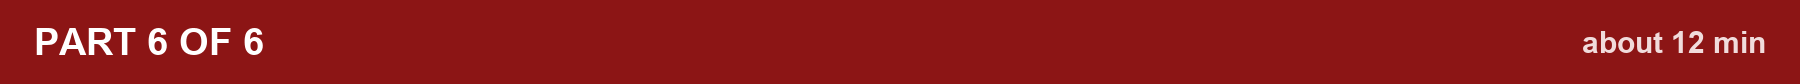

> **In this part:** pick your own question, change a few lines, and tell the room what you find.


* Pick a question, change the lines marked `change these`, run the cell, and see what the knees show
* Then tell the room: your question, the held-out AUC, and what the shapes looked like
* **The next cell shows every column you can use**: the table from Part 3, again
* Count a group before you trust it, e.g. `(cohort.prev_knee_surgery == 1).sum()`. A group of 8 knees can't teach you much
* How to write a group:
  * `cohort.kl >= 3`: KL 3 or 4
  * `cohort.sex == "Female"`
  * `cohort.nrs_pain_future >= 4`
  * `(cohort.age >= 65) & (cohort.kl == 2)`: join two conditions with `&`, each in brackets
* Ideas:
  * Does the sex difference hold in every KL grade? Change `KL_GRADE` in Part 5
  * Among KL 3 and 4 knees, do the ones replaced within 8 years look different? That's the template cell as it stands
  * Will a pain-free knee become painful? Among the 149 knees with `nrs_pain_current == 0`, 33 later have `nrs_pain_future >= 2`
  * Previous knee surgery, `prev_knee_surgery`, against none
  * Older against younger knees, within one KL grade
* Stuck? Ask Colab's AI assistant to change a cell for you, or use the prompts in [`OpenMSK_LLM_prompts.md`](https://github.com/NeuromuscularInsightLab/Stanford_Musculoskeletal_Imaging_Workshop/blob/main/notebooks/OpenMSK_LLM_prompts.md)

In [ ]:
# Every column you can use: the table from Part 3, again
dictionary

In [ ]:
# ---- change these ----
NAME = "tkr_kl34"                                # a short name, used for the saved pictures
POSITIVE = cohort.tkr_8y == 1                    # the group you're interested in
NEGATIVE = cohort.tkr_8y == 0                    # the knees you compare them with
SUBSET = cohort.kl >= 3                          # only these knees. Use None for all 500
ENDS = ("−3 SD: not replaced end", "+3 SD: replaced end")
# ----------------------
my_knees = predict_then_look(POSITIVE, NEGATIVE, subset=SUBSET, name=NAME, ends=ENDS)

## Many scans, one sheet

* For your own results: unzip each one into its own folder, then flatten them
* Each row is a knee

In [ ]:
def compile_results(folders):
    """One row per results folder: the thickness table plus both B-scores and their fit errors."""
    rows = []
    for folder in map(Path, folders):
        row = {"scan": folder.name}
        for csv in folder.glob("*_results.csv"):          # thickness (and T2, if present)
            row.update(pd.read_csv(csv).iloc[0].to_dict())
        for key, name in (("bone_only", "NSM_bone_only_recon_params.json"), ("bone_cart", "NSM_recon_params.json")):
            p = folder / name
            if p.exists():                                # only if that shape model was run
                params = json.loads(p.read_text())
                row[f"bscore_{key}"] = params["Bscore"]
                row[f"assd_bone_mm_{key}"] = params["assd_bone_mm"]
        rows.append(row)
    return pd.DataFrame(rows)

# Here with one folder. For yours: compile_results(Path("my_results").iterdir())
compile_results([FOLDER])[["scan", "med_wb_fem_cart_mm_mean", "lat_wb_fem_cart_mm_mean", "bscore_bone_only", "assd_bone_mm_bone_only"]]

**Next:**

* **Run OpenMSK yourself**, so nothing leaves your machine: https://github.com/gattia/OpenMSK. It needs an NVIDIA GPU. The repo's README and CLAUDE.md are written so a coding agent can set it up with you
* **Research use only.** Not for clinical decisions

**Try these with an LLM.** Give it the teaching sheet, its data dictionary and [`OpenMSK_LLM_prompts.md`](https://github.com/NeuromuscularInsightLab/Stanford_Musculoskeletal_Imaging_Workshop/blob/main/notebooks/OpenMSK_LLM_prompts.md), which has a prompt for each:

* Does B-score or thickness predict replacement better, once you account for KL?
* Is the femur or the tibia thinning first?
* Are female and male knees on the same line?
* When do `bscore_bone` and `bscore_bone_cart` disagree?

If OpenMSK contributes to your work, please cite Goyal A et al., *Osteoarthritis and Cartilage Open*, 2026;8(4):100886, [doi:10.1016/j.ocarto.2026.100886](https://www.sciencedirect.com/science/article/pii/S2665913126001445). For the shape model: Gatti AA et al., *IEEE TMI*, 2025;44(3):1140-1152.